# TASK 3: CAR PRICE PREDICTION WITH MACHINE LEARNING

## 1. Introduction

Car price prediction is a machine learning project that aims to estimate the selling price of used cars based on different features such as car brand, manufacturing year, mileage, fuel type and transmission.

In this project, regression algorithms are used to analyse car-related data and predict the selling price of used cars.


The dataset contains information about used cars, including their name, manufacturing year, selling price, present price, kilometres driven, fuel type, seller type, transmission and previous owners.

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset
df = pd.read_csv("car data.csv")

# Display the first five rows
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 2. Dataset Inspection

In this section, we inspect the dataset to understand its structure, size, column names and data types.

This helps us identify missing values and prepare the dataset for further analysis.

In [3]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Shape: (301, 9)

Column Names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB

Statistical Summary:


,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


## 3. Data Cleaning

Data cleaning is performed to improve the quality of the dataset before building the machine learning model.

In this step, we check for missing values, duplicate records and inconsistent categorical values. We also remove duplicate records and standardise text values.

In [4]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of Duplicate Rows:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Remove extra spaces and standardise categorical values
categorical_columns = ['Car_Name', 'Fuel_Type', 'Seller_Type', 'Transmission']

for column in categorical_columns:
    df[column] = df[column].astype(str).str.strip().str.title()

# Display the updated dataset shape
print("\nDataset Shape After Cleaning:", df.shape)

# Check missing values again
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Number of Duplicate Rows: 2

Dataset Shape After Cleaning: (299, 9)

Missing Values After Cleaning:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64


### Data Cleaning Observations

1. The original dataset contained 301 records and 9 columns.
2. No missing values were found in the dataset.
3. Two duplicate records were identified and removed.
4. After removing duplicates, 299 records remained.
5. Categorical values were standardised to maintain consistency.
6. The cleaned dataset is ready for feature engineering.

## 4. Feature Engineering

Feature engineering is the process of creating new useful features from existing data.

In this project:
- Car Age is calculated using the manufacturing year.
- Brand is extracted from the car name.

These new features can help the machine learning model understand the factors affecting car prices.

In [5]:
# Calculate the current year
current_year = pd.Timestamp.today().year

# Create a new feature for car age
df['Car_Age'] = current_year - df['Year']

# Extract the brand from the car name
df['Brand'] = df['Car_Name'].str.split().str[0]

# Display the updated dataset
df[['Car_Name', 'Brand', 'Year', 'Car_Age']].head()

,Car_Name,Brand,Year,Car_Age
0,Ritz,Ritz,2014,12
1,Sx4,Sx4,2013,13
2,Ciaz,Ciaz,2017,9
3,Wagon R,Wagon,2011,15
4,Swift,Swift,2014,12


### Feature Engineering Observations

1. A new column named Car_Age was created using the manufacturing year.
2. The Brand column was extracted from the Car_Name column.
3. These features provide additional information about each used car.
4. The updated dataset is ready for Exploratory Data Analysis (EDA).

## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of car prices and the relationship between car features and selling prices.

In this section, we visualise:
- Distribution of selling prices.
- Selling price according to fuel type.
- Relationship between car age and selling price.

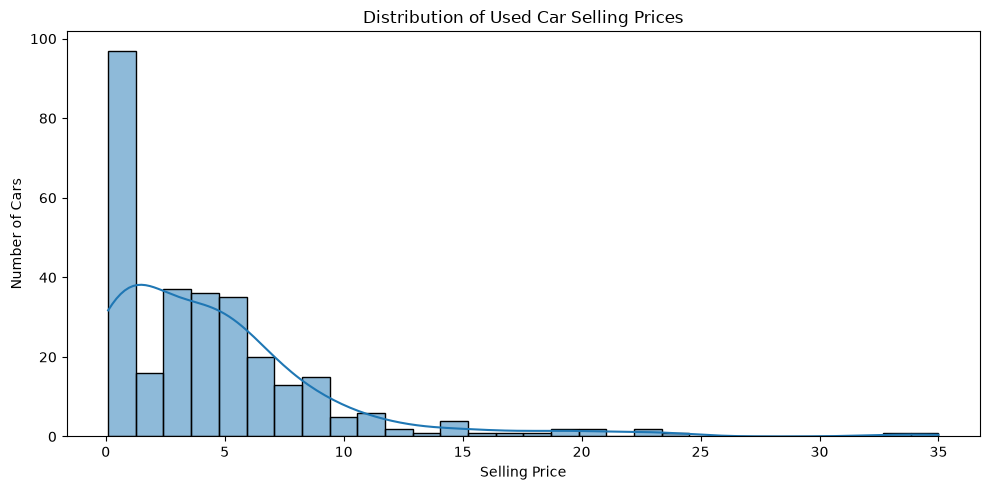

In [6]:
# Plot the distribution of selling prices
plt.figure(figsize=(10, 5))

sns.histplot(df['Selling_Price'], bins=30, kde=True)

plt.title('Distribution of Used Car Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')
plt.tight_layout()
plt.show()

### Selling Price Distribution Observations

1. Most used cars have selling prices below 5.
2. Only a few cars have very high selling prices.
3. The selling price distribution is positively skewed (right-skewed).
4. This indicates that most cars are available at lower prices compared to a small number of expensive cars.

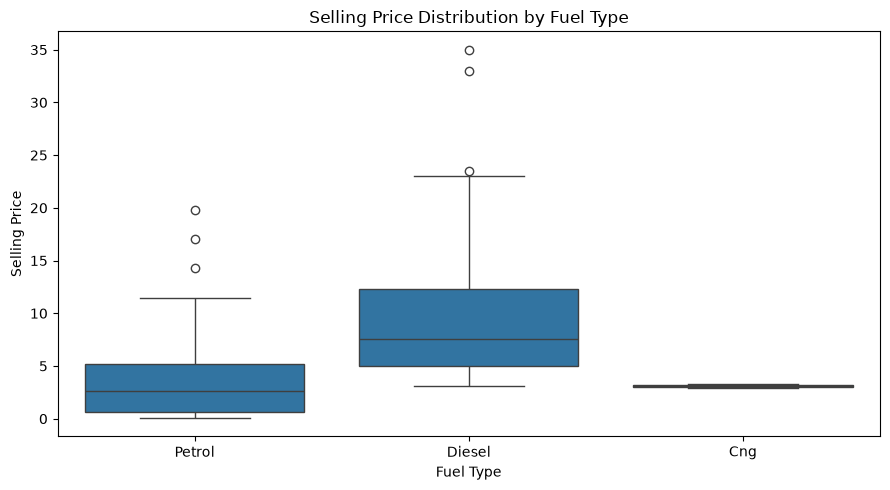

In [7]:
# Compare selling prices across different fuel types
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Fuel_Type',
    y='Selling_Price'
)

plt.title('Selling Price Distribution by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')
plt.tight_layout()
plt.show()

### Fuel Type Analysis Observations

1. Diesel cars have a higher median selling price compared to petrol cars.
2. Petrol cars generally have lower selling prices.
3. CNG cars show a narrow selling price range in this dataset.
4. Some petrol and diesel cars have high selling prices compared to the majority of cars.

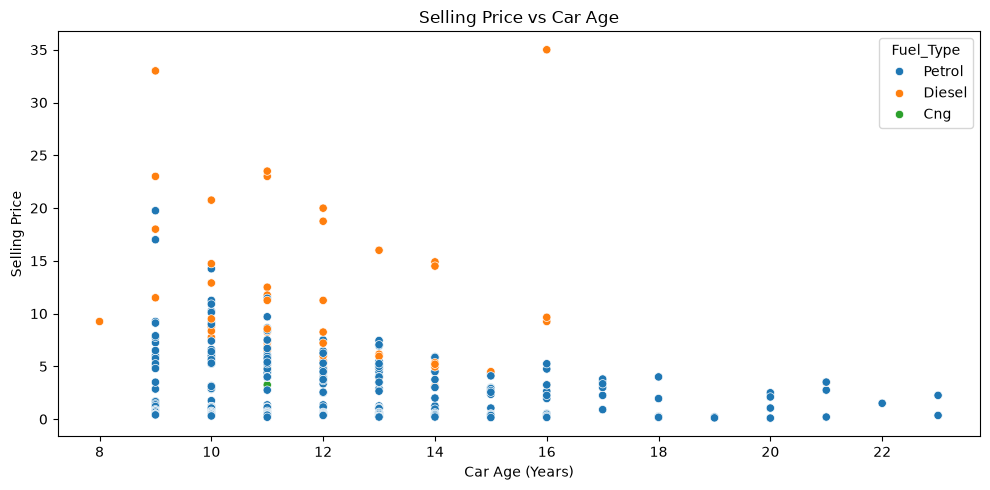

In [8]:
# Analyse the relationship between car age and selling price
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='Car_Age',
    y='Selling_Price',
    hue='Fuel_Type'
)

plt.title('Selling Price vs Car Age')
plt.xlabel('Car Age (Years)')
plt.ylabel('Selling Price')
plt.tight_layout()
plt.show()

## 6. Encoding Categorical Variables

Machine learning models work with numerical data. Therefore, categorical features such as Brand, Fuel_Type, Seller_Type and Transmission must be converted into numerical form.

In this project, One-Hot Encoding is used to convert categorical values into separate numerical columns.

In [9]:
# Select input features and target variable
X = df.drop(columns=['Selling_Price', 'Car_Name', 'Year'])
y = df['Selling_Price']

# Identify categorical and numerical columns
categorical_features = ['Brand', 'Fuel_Type', 'Seller_Type', 'Transmission']
numerical_features = [
    'Present_Price',
    'Kms_Driven',
    'Owner',
    'Car_Age'
]

# Apply One-Hot Encoding to categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numerical', SimpleImputer(strategy='median'), numerical_features)
    ]
)

# Display the selected features
print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   Present_Price  Kms_Driven Fuel_Type Seller_Type Transmission  Owner  \
0           5.59       27000    Petrol      Dealer       Manual      0   
1           9.54       43000    Diesel      Dealer       Manual      0   
2           9.85        6900    Petrol      Dealer       Manual      0   
3           4.15        5200    Petrol      Dealer       Manual      0   
4           6.87       42450    Diesel      Dealer       Manual      0   

   Car_Age  Brand  
0       12   Ritz  
1       13    Sx4  
2        9   Ciaz  
3       15  Wagon  
4       12  Swift  

Target Variable:
0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64


## 7. Feature Correlation Heatmap

A correlation heatmap is used to understand the relationship between numerical features and the selling price.

The categorical features are converted into numerical columns using One-Hot Encoding before calculating correlations.

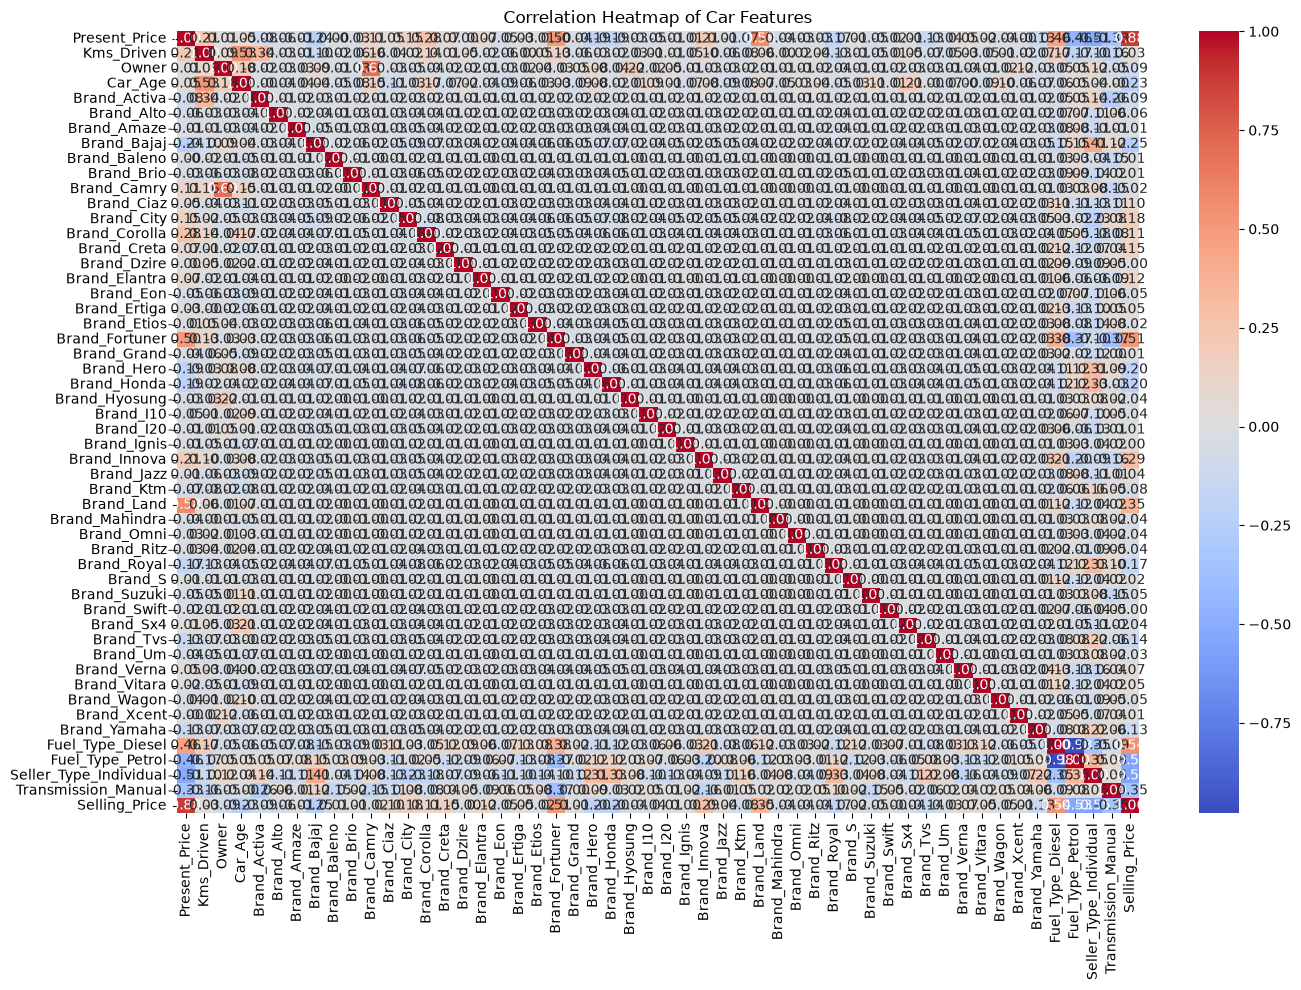

In [10]:
# Convert categorical features into numerical columns for correlation analysis
encoded_data = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Add the target variable to the encoded data
encoded_data['Selling_Price'] = y

# Calculate the correlation matrix
correlation_matrix = encoded_data.corr()

# Plot the correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Car Features')
plt.tight_layout()
plt.show()

### Correlation Heatmap Observations

1. The heatmap shows the correlation between numerical and encoded categorical car features.
2. Present_Price has a strong positive relationship with Selling_Price.
3. Car_Age and Kms_Driven help us understand how the age and usage of a car relate to its selling price.
4. The encoded categorical features show differences in selling prices across categories.
5. Correlation helps identify relationships between features but does not prove causation.

## 8. Train-Test Split

The dataset is divided into two parts:

- Training data (80%): Used to train the machine learning models.
- Testing data (20%): Used to evaluate model performance.

The split is performed using a fixed random state to make the results reproducible.

In [11]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display the shapes of training and testing data
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (239, 8)
Testing Features: (60, 8)
Training Target: (239,)
Testing Target: (60,)


## 9. Model Training

In this section, two machine learning regression algorithms are trained to predict used car selling prices.

1. Linear Regression: A regression algorithm that models the relationship between input features and the target variable.
2. Random Forest Regressor: An ensemble learning algorithm that combines multiple decision trees to make predictions.

Both models are trained using the same training dataset.

In [12]:
# Create the Linear Regression pipeline
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Create the Random Forest Regression pipeline
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# Train the Linear Regression model
linear_model.fit(X_train, y_train)

# Train the Random Forest model
random_forest_model.fit(X_train, y_train)

print("Both regression models trained successfully.")

Both regression models trained successfully.


## 10. Model Evaluation

The trained regression models are evaluated using three performance metrics:

1. Mean Absolute Error (MAE)
2. Root Mean Squared Error (RMSE)
3. R-squared (R²) Score

These metrics help compare the prediction accuracy of Linear Regression and Random Forest Regression.

In [13]:
# Generate predictions using both models
linear_predictions = linear_model.predict(X_test)
rf_predictions = random_forest_model.predict(X_test)

# Create a function to calculate evaluation metrics
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return mae, rmse, r2

# Evaluate Linear Regression
linear_mae, linear_rmse, linear_r2 = evaluate_model(
    y_test, linear_predictions
)

# Evaluate Random Forest
rf_mae, rf_rmse, rf_r2 = evaluate_model(
    y_test, rf_predictions
)

# Display the comparison
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [linear_mae, rf_mae],
    'RMSE': [linear_rmse, rf_rmse],
    'R2 Score': [linear_r2, rf_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.348138,2.388979,0.778560
1,Random Forest,1.329385,3.195857,0.603717


### Model Evaluation Observations

1. Both Linear Regression and Random Forest Regression were trained and evaluated.
2. Linear Regression achieved an MAE of approximately 1.35.
3. Random Forest achieved an MAE of approximately 1.33.
4. Linear Regression achieved a lower RMSE of approximately 2.39.
5. Linear Regression achieved an R² score of approximately 0.78.
6. Based on RMSE and R² score, Linear Regression performed better overall on the test dataset.
7. Therefore, Linear Regression is selected as the best-performing model.

## 11. Feature Importance Analysis

Feature importance helps identify which input features contribute most to the predictions made by a machine learning model.

In this project, feature importance is extracted from the trained Random Forest Regressor and displayed using a bar chart.

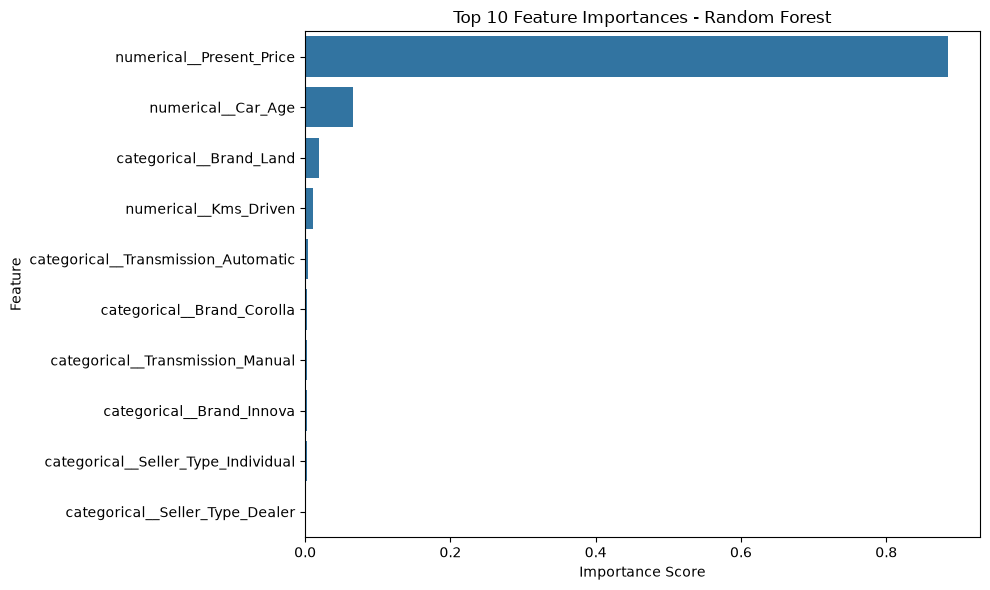

In [14]:
# Get feature names after preprocessing
feature_names = random_forest_model.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance values from Random Forest
importance_values = random_forest_model.named_steps['model'].feature_importances_

# Create a feature importance DataFrame
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Plot the top 10 important features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Feature Importances - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 12. Conclusion

This project successfully developed machine learning regression models to predict the selling prices of used cars.

The following activities were performed:

1. Loaded and inspected the CarDekho dataset.
2. Cleaned the data by removing duplicate records and checking missing values.
3. Created new features such as Car_Age and Brand.
4. Performed Exploratory Data Analysis using histograms, box plots and scatter plots.
5. Applied One-Hot Encoding to categorical features.
6. Analysed feature correlations using a heatmap.
7. Divided the dataset into training and testing sets.
8. Trained Linear Regression and Random Forest Regression models.
9. Evaluated both models using MAE, RMSE and R² score.
10. Analysed feature importance using Random Forest.

Linear Regression performed better overall on the test dataset, achieving an R² score of approximately 0.78.

Overall, this project demonstrates how Python and machine learning techniques can be used to analyse used-car data and predict selling prices.